# Notebook 1: Data Loading, EDA, Preprocessing and Splits

Thesis: *Deep Learning-Based Anomaly Detection in Financial Transaction Time Series: A Comparative Study of AE and VAE Architectures*

What this notebook does, for both datasets (IEEE-CIS and BAF Base):
1. Loads the raw data straight from the zip files in `../Dataset`.
2. Runs basic exploratory data analysis (EDA) and saves figures to `../Figures`.
3. Splits the data **by time** into a training period, a labelled validation period and a test period.
4. Keeps only **normal** transactions in the training period (unsupervised training, no resampling).
5. Fits imputation, encoding and Min-Max scaling on the training normals only, then applies them to every other split (no leakage).
6. Saves ready-to-train arrays to `../Processed` for Notebook 2.

Split design (agreed after the first marker's feedback):

| Split | Role | Labels used? |
|---|---|---|
| Train (normals only) | Fit the AE / VAE | No |
| Early-stop (10% of train normals, random) | Early stopping and learning-rate schedule | No |
| Validation period (all rows) | Choose the calibrated threshold | Yes, label-assisted, declared in the thesis |
| Test period (all rows, natural fraud rate) | Final reported results | Only for scoring |

**At a glance**

| | |
|---|---|
| Run on | Laptop (CPU is enough, no model training here) |
| Run time | A few minutes, mostly reading the two zip files |
| Reads | `../Dataset/ieee-fraud-detection.zip`, `../Dataset/dataset__NeurIIPS.zip` |
| Writes | `../Processed/ieee.npz`, `../Processed/baf.npz`, `split_summary.csv`, `prep_meta.json`; EDA figures in `../Figures/` |
| Run order | Step 1 of 6. Run this first. |

In [2]:
import os, json, zipfile, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)

BASE = os.path.abspath("..")                       # the 04_Final_Thesis folder
DATA_DIR = os.path.join(BASE, "Dataset")
FIG_DIR  = os.path.join(BASE, "Figures")
OUT_DIR  = os.path.join(BASE, "Processed")
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

IEEE_ZIP = os.path.join(DATA_DIR, "ieee-fraud-detection.zip")
BAF_ZIP  = os.path.join(DATA_DIR, "dataset__NeurIIPS.zip")

# Readable figures for the thesis (fonts stay legible at 100% zoom in Word)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 12,
                     "axes.titlesize": 13, "axes.labelsize": 12,
                     "font.family": "Times New Roman"})
sns.set_style("whitegrid")

def savefig(name):
    path = os.path.join(FIG_DIR, name)
    plt.savefig(path, bbox_inches="tight")
    print("saved", path)

print("Dataset folder:", DATA_DIR)
print(os.listdir(DATA_DIR))

Dataset folder: ..\Dataset
['dataset__NeurIIPS.zip', 'ieee-fraud-detection.zip']


## Shared preprocessing helpers

All statistics (medians, modes, category codes, min and max) are learned from the **training normals only**.
Categories that appear later but were never seen in training are mapped to the training mode.
Values outside the training range are **not** clipped, because an unusually large value is exactly
the kind of signal the reconstruction error should pick up.

In [4]:
def fit_preprocessor(train_df, num_cols, cat_cols, onehot_cols=()):
    """Learn imputation, encoding and scaling from training normals only."""
    p = {"num_cols": list(num_cols), "cat_cols": list(cat_cols), "onehot_cols": list(onehot_cols)}
    p["median"] = train_df[num_cols].median().to_dict()
    p["mode"] = {c: train_df[c].mode(dropna=True).iloc[0] for c in list(cat_cols) + list(onehot_cols)}
    # label encoding: category -> integer code, learned on training normals
    p["codes"] = {c: {v: i for i, v in enumerate(sorted(train_df[c].fillna(p["mode"][c]).astype(str).unique()))}
                  for c in cat_cols}
    p["onehot_levels"] = {c: sorted(train_df[c].fillna(p["mode"][c]).astype(str).unique()) for c in onehot_cols}
    X = _encode(train_df, p, fit_scale=True)
    return p, X

def _encode(df, p, fit_scale=False):
    parts, names = [], []
    num = df[p["num_cols"]].fillna(p["median"]).astype("float32")
    parts.append(num.values); names += p["num_cols"]
    for c in p["cat_cols"]:
        s = df[c].fillna(p["mode"][c]).astype(str)
        mode_code = p["codes"][c][str(p["mode"][c])]
        parts.append(s.map(p["codes"][c]).fillna(mode_code).values.reshape(-1, 1).astype("float32"))
        names.append(c)
    for c in p["onehot_cols"]:
        s = df[c].fillna(p["mode"][c]).astype(str)
        s = s.where(s.isin(p["onehot_levels"][c]), str(p["mode"][c]))
        for lvl in p["onehot_levels"][c]:
            parts.append((s == lvl).values.reshape(-1, 1).astype("float32"))
            names.append(f"{c}={lvl}")
    X = np.hstack(parts).astype("float32")
    if fit_scale:
        p["min"] = X.min(axis=0)
        rng = X.max(axis=0) - p["min"]
        p["range"] = np.where(rng == 0, 1.0, rng).astype("float32")
        p["feature_names"] = names
    return ((X - p["min"]) / p["range"]).astype("float32")

def transform(df, p):
    return _encode(df, p, fit_scale=False)

def split_summary(name, parts):
    rows = []
    for split, y in parts.items():
        rows.append({"dataset": name, "split": split, "rows": int(len(y)),
                     "fraud": int(y.sum()), "fraud_rate_%": round(100 * float(y.mean()), 3)})
    return pd.DataFrame(rows)

---
# Part A: IEEE-CIS Fraud Detection

Only `train_transaction.csv` and `train_identity.csv` are used. Kaggle's own "test" files have no labels,
so they cannot be used for evaluation. The two files are joined on `TransactionID` (left join, because
only about a quarter of transactions have identity information).

In [6]:
t0 = time.time()
with zipfile.ZipFile(IEEE_ZIP) as z:
    trans = pd.read_csv(z.open("train_transaction.csv"))
    ident = pd.read_csv(z.open("train_identity.csv"))
ieee = trans.merge(ident, on="TransactionID", how="left")
del trans, ident

# reduce memory: float64 -> float32
f64 = ieee.select_dtypes("float64").columns
ieee[f64] = ieee[f64].astype("float32")

print("Shape after merge:", ieee.shape, f"| loaded in {time.time()-t0:.0f}s")
print("Fraud rate: {:.3%}".format(ieee["isFraud"].mean()))
print("Rows with identity info: {:.1%}".format(ieee["id_01"].notna().mean()))

Shape after merge: (590540, 434) | loaded in 38s
Fraud rate: 3.499%
Rows with identity info: 24.4%


## A.1 EDA

saved ..\Figures\ieee_class_distribution.png


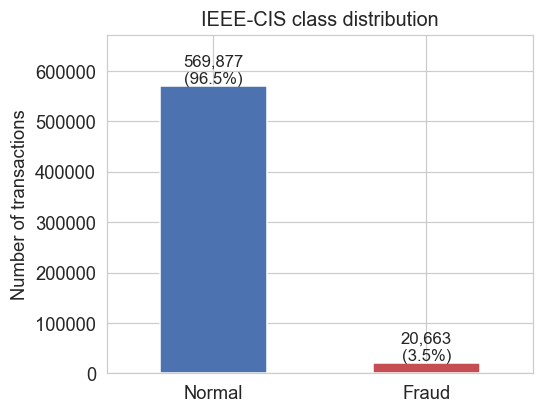

In [8]:
# Class distribution
counts = ieee["isFraud"].value_counts().sort_index()
ax = counts.rename({0: "Normal", 1: "Fraud"}).plot.bar(color=["#4C72B0", "#C44E52"], figsize=(5, 4), rot=0)
ax.set_ylabel("Number of transactions"); ax.set_xlabel("")
ax.set_title("IEEE-CIS class distribution")
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}\n({v/counts.sum():.1%})", ha="center", va="bottom", fontsize=11)
ax.set_ylim(0, counts.max() * 1.18)
savefig("ieee_class_distribution.png"); plt.show()

ipykernel_33224\621507469.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ieee["day"] = (ieee["TransactionDT"] // 86400).astype(int)


saved ..\Figures\ieee_fraud_over_time.png


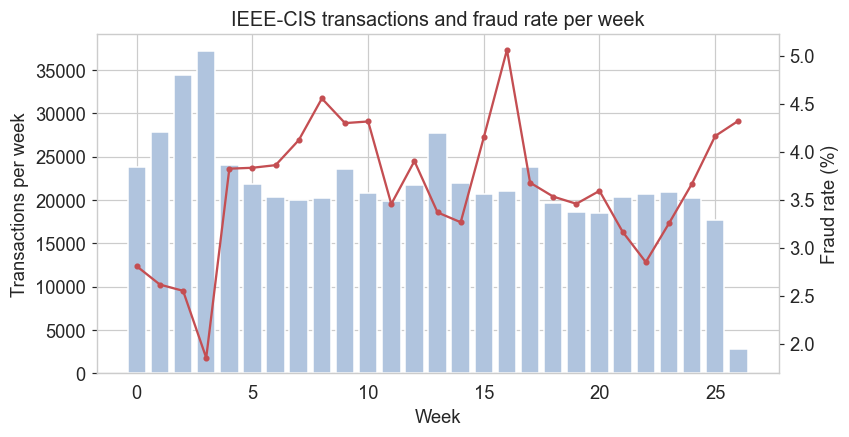

In [9]:
# Fraud rate over time (TransactionDT is seconds from an unknown reference point)
ieee["day"] = (ieee["TransactionDT"] // 86400).astype(int)
weekly = ieee.groupby(ieee["day"] // 7)["isFraud"].agg(["size", "mean"])
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.bar(weekly.index, weekly["size"], color="#B0C4DE", label="Transactions per week")
ax1.set_xlabel("Week"); ax1.set_ylabel("Transactions per week")
ax2 = ax1.twinx()
ax2.plot(weekly.index, 100 * weekly["mean"], color="#C44E52", marker="o", ms=3, label="Fraud rate (%)")
ax2.set_ylabel("Fraud rate (%)"); ax2.grid(False)
ax1.set_title("IEEE-CIS transactions and fraud rate per week")
savefig("ieee_fraud_over_time.png"); plt.show()

Columns with any missing values: 414 of 435
Columns with >90% missing: 12
saved ..\Figures\ieee_missing_values.png


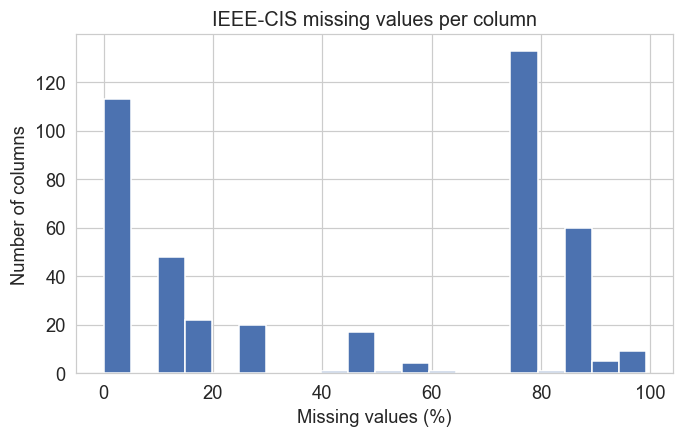

In [10]:
# Missing values
miss = ieee.isna().mean().sort_values(ascending=False)
print("Columns with any missing values:", (miss > 0).sum(), "of", ieee.shape[1])
print("Columns with >90% missing:", (miss > 0.9).sum())
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(100 * miss.values, bins=20, color="#4C72B0", edgecolor="white")
ax.set_xlabel("Missing values (%)"); ax.set_ylabel("Number of columns")
ax.set_title("IEEE-CIS missing values per column")
savefig("ieee_missing_values.png"); plt.show()

saved ..\Figures\ieee_amount_by_class.png


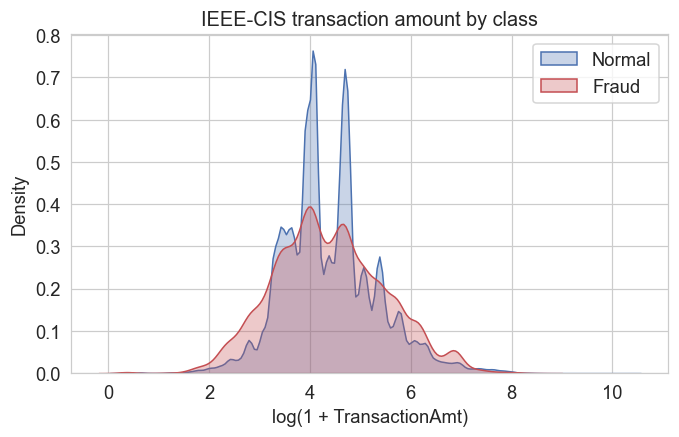

            count    mean     std   min    25%   50%    75%       max
isFraud                                                              
0        569877.0  134.51  239.40  0.25  43.97  68.5  120.0  31937.39
1         20663.0  149.24  232.21  0.29  35.04  75.0  161.0   5191.00


In [11]:
# Transaction amount by class (log scale because the amount is heavily skewed)
fig, ax = plt.subplots(figsize=(7, 4))
for lab, name, col in [(0, "Normal", "#4C72B0"), (1, "Fraud", "#C44E52")]:
    sns.kdeplot(np.log1p(ieee.loc[ieee.isFraud == lab, "TransactionAmt"]), ax=ax,
                label=name, color=col, fill=True, alpha=0.3, common_norm=False)
ax.set_xlabel("log(1 + TransactionAmt)"); ax.set_ylabel("Density"); ax.legend()
ax.set_title("IEEE-CIS transaction amount by class")
savefig("ieee_amount_by_class.png"); plt.show()
print(ieee.groupby("isFraud")["TransactionAmt"].describe().round(2))

## A.2 Feature selection and types

* Dropped: `TransactionID` (key), `TransactionDT` and `day` (time index, used only for splitting),
  and columns with more than 90% missing values (they carry almost no information and would be mostly imputed).
* `TransactionAmt` is log-transformed before scaling because it is very skewed (see the plot above).
* Categorical columns are the text columns plus the known categorical codes in the Kaggle data description
  (`card1` to `card6`, `addr1`, `addr2`, `P_emaildomain`, `R_emaildomain`, `M1` to `M9`, `DeviceType`, `DeviceInfo`, `id_12` to `id_38`).
  These are label-encoded, as stated in the proposal.

In [13]:
MISS_LIMIT = 0.90
drop_cols = ["TransactionID", "TransactionDT", "day", "isFraud"]
high_miss = miss[miss > MISS_LIMIT].index.tolist()

known_cat = (["ProductCD", "card1", "card2", "card3", "card4", "card5", "card6", "addr1", "addr2",
              "P_emaildomain", "R_emaildomain", "DeviceType", "DeviceInfo"]
             + [f"M{i}" for i in range(1, 10)] + [f"id_{i}" for i in range(12, 39)])
feature_cols = [c for c in ieee.columns if c not in drop_cols and c not in high_miss]
ieee_cat = [c for c in feature_cols if c in known_cat or ieee[c].dtype == object]
ieee_num = [c for c in feature_cols if c not in ieee_cat]

ieee["TransactionAmt"] = np.log1p(ieee["TransactionAmt"]).astype("float32")

print("Dropped for >90% missing:", len(high_miss))
print("Numeric features:", len(ieee_num), "| Categorical features:", len(ieee_cat),
      "| Total:", len(ieee_num) + len(ieee_cat))

Dropped for >90% missing: 12
Numeric features: 378 | Categorical features: 41 | Total: 419


## A.3 Time-based split

Rows are sorted by `TransactionDT`. The first 70% is the training period, the next 15% the validation period
and the last 15% the test period. Fraud in the training period is removed from training
(the model must only learn what normal looks like). This also means the test period is genuinely later in time
than anything the model has seen, which is closer to how a bank would use it.

In [15]:
ieee = ieee.sort_values("TransactionDT").reset_index(drop=True)
n = len(ieee)
i_tr, i_va = int(0.70 * n), int(0.85 * n)
tr_period, va_period, te_period = ieee.iloc[:i_tr], ieee.iloc[i_tr:i_va], ieee.iloc[i_va:]

tr_normal = tr_period[tr_period["isFraud"] == 0]
es_mask = np.random.RandomState(SEED).rand(len(tr_normal)) < 0.10      # 10% for early stopping
fit_part, es_part = tr_normal[~es_mask], tr_normal[es_mask]

print("Training-period fraud removed from training:", int(tr_period["isFraud"].sum()))
print("Day ranges -> train:", tr_period.day.min(), "-", tr_period.day.max(),
      "| val:", va_period.day.min(), "-", va_period.day.max(),
      "| test:", te_period.day.min(), "-", te_period.day.max())

Training-period fraud removed from training: 14538
Day ranges -> train: 1 - 120 | val: 120 - 152 | test: 152 - 182


In [16]:
t0 = time.time()
ieee_p, X_tr = fit_preprocessor(fit_part, ieee_num, ieee_cat)
X_es = transform(es_part, ieee_p)
X_va = transform(va_period, ieee_p); y_va = va_period["isFraud"].values.astype("int8")
X_te = transform(te_period, ieee_p); y_te = te_period["isFraud"].values.astype("int8")
print(f"Preprocessed in {time.time()-t0:.0f}s | features: {X_tr.shape[1]}")

np.savez_compressed(os.path.join(OUT_DIR, "ieee.npz"),
                    X_train=X_tr, X_es=X_es, X_val=X_va, y_val=y_va, X_test=X_te, y_test=y_te,
                    feature_names=np.array(ieee_p["feature_names"]))

ieee_summary = split_summary("IEEE-CIS", {
    "train (normals)": np.zeros(len(X_tr)), "early-stop (normals)": np.zeros(len(X_es)),
    "validation": y_va, "test": y_te})
ieee_summary

Preprocessed in 28s | features: 419


,dataset,split,rows,fraud,fraud_rate_%
0,IEEE-CIS,train (normals),358788,0,0.000
1,IEEE-CIS,early-stop (normals),40052,0,0.000
2,IEEE-CIS,validation,88581,3042,3.434
3,IEEE-CIS,test,88581,3083,3.480


In [17]:
# Sanity checks
print("Any NaN left:", np.isnan(X_tr).any() or np.isnan(X_va).any() or np.isnan(X_te).any())
print("Train range:", X_tr.min().round(3), "to", X_tr.max().round(3))
print("Test share of values outside [0,1]: {:.3%}".format(((X_te < 0) | (X_te > 1)).mean()))
del ieee, tr_period, va_period, te_period, tr_normal, fit_part, es_part, X_tr, X_es, X_va, X_te

Any NaN left: False
Train range: 0.0 to 1.0
Test share of values outside [0,1]: 0.138%


---
# Part B: Bank Account Fraud (BAF) Suite, Base variant

The label column is `fraud_bool`. The `month` column (0 to 7) is used for the time-based split:
months 0 to 5 for training, month 6 for validation and month 7 for testing. This follows the split
used by the dataset authors, who trained on the first six months and tested on the last two.

Notes on BAF:
* Some numeric columns use **-1** to mean "missing" (for example `prev_address_months_count`).
  These are converted to NaN and median-imputed, the same rule used for IEEE-CIS.
* The five text columns have only a handful of levels each, so they are **one-hot encoded**.
  Label encoding would invent an order that does not exist and only saves a few columns here.
* Columns that are constant in the training data are dropped.

In [19]:
t0 = time.time()
with zipfile.ZipFile(BAF_ZIP) as z:
    baf = pd.read_csv(z.open("Base.csv"))
print("Shape:", baf.shape, f"| loaded in {time.time()-t0:.0f}s")
print("Fraud rate: {:.3%}".format(baf["fraud_bool"].mean()))
baf.groupby("month")["fraud_bool"].agg(rows="size", fraud="sum", fraud_rate="mean").round(4)

Shape: (1000000, 32) | loaded in 7s
Fraud rate: 1.103%


,rows,fraud,fraud_rate
month,,,
0,132440,1500,0.0113
1,127620,1198,0.0094
2,136979,1198,0.0087
3,150936,1392,0.0092
4,127691,1452,0.0114
5,119323,1411,0.0118
6,108168,1450,0.0134
7,96843,1428,0.0147


## B.1 EDA

saved ..\Figures\baf_class_distribution.png


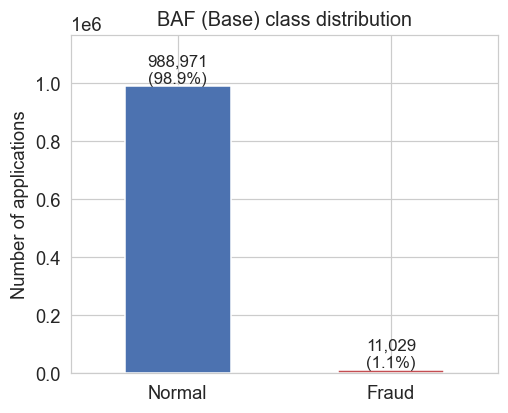

saved ..\Figures\baf_fraud_over_time.png


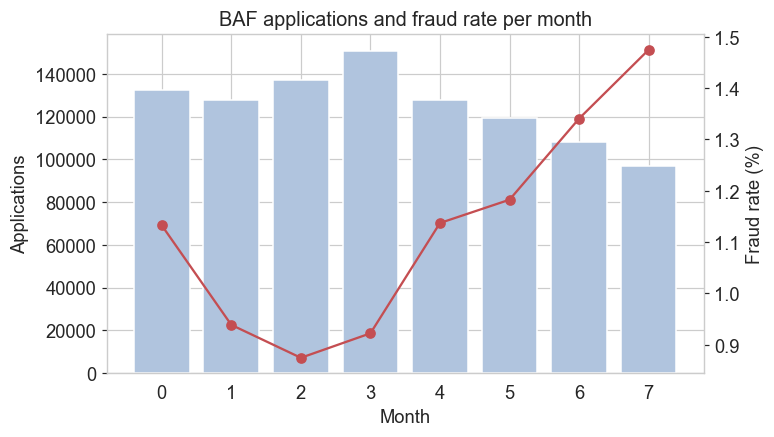

In [21]:
counts = baf["fraud_bool"].value_counts().sort_index()
ax = counts.rename({0: "Normal", 1: "Fraud"}).plot.bar(color=["#4C72B0", "#C44E52"], figsize=(5, 4), rot=0)
ax.set_ylabel("Number of applications"); ax.set_xlabel("")
ax.set_title("BAF (Base) class distribution")
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}\n({v/counts.sum():.1%})", ha="center", va="bottom", fontsize=11)
ax.set_ylim(0, counts.max() * 1.18)
savefig("baf_class_distribution.png"); plt.show()

m = baf.groupby("month")["fraud_bool"].agg(["size", "mean"])
fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.bar(m.index, m["size"], color="#B0C4DE"); ax1.set_xlabel("Month"); ax1.set_ylabel("Applications")
ax2 = ax1.twinx(); ax2.plot(m.index, 100 * m["mean"], color="#C44E52", marker="o")
ax2.set_ylabel("Fraud rate (%)"); ax2.grid(False)
ax1.set_title("BAF applications and fraud rate per month")
savefig("baf_fraud_over_time.png"); plt.show()

In [22]:
# -1 used as a missing-value code
# Columns where -1 means "missing" (per the BAF datasheet). credit_risk_score and
# intended_balcon_amount can be genuinely negative, so they are left as they are.
neg_cols = ["prev_address_months_count", "current_address_months_count", "bank_months_count",
            "session_length_in_minutes", "device_distinct_emails_8w"]
print("Share of -1 (missing) values:", {c: f"{(baf[c] == -1).mean():.1%}" for c in neg_cols})

# Numeric features: normal vs fraud means (a quick look at which features differ)
num_all = [c for c in baf.select_dtypes("number").columns if c not in ("fraud_bool", "month")]
diff = baf.groupby("fraud_bool")[num_all].mean().T
diff.columns = ["normal_mean", "fraud_mean"]
diff["ratio"] = (diff["fraud_mean"] / diff["normal_mean"].replace(0, np.nan)).round(2)
diff.sort_values("ratio", ascending=False).round(3)

Share of -1 (missing) values: {'prev_address_months_count': '71.3%', 'current_address_months_count': '0.4%', 'bank_months_count': '25.4%', 'session_length_in_minutes': '0.2%', 'device_distinct_emails_8w': '0.0%'}


,normal_mean,fraud_mean,ratio
foreign_request,0.025,0.050,2.02
proposed_credit_limit,512.303,833.987,1.63
credit_risk_score,130.470,177.590,1.36
current_address_months_count,86.273,114.801,1.33
email_is_free,0.528,0.661,1.25
income,0.561,0.687,1.22
customer_age,33.609,40.859,1.22
session_length_in_minutes,7.537,8.230,1.09
device_distinct_emails_8w,1.018,1.079,1.06
zip_count_4w,1572.139,1622.312,1.03


saved ..\Figures\baf_features_by_class.png


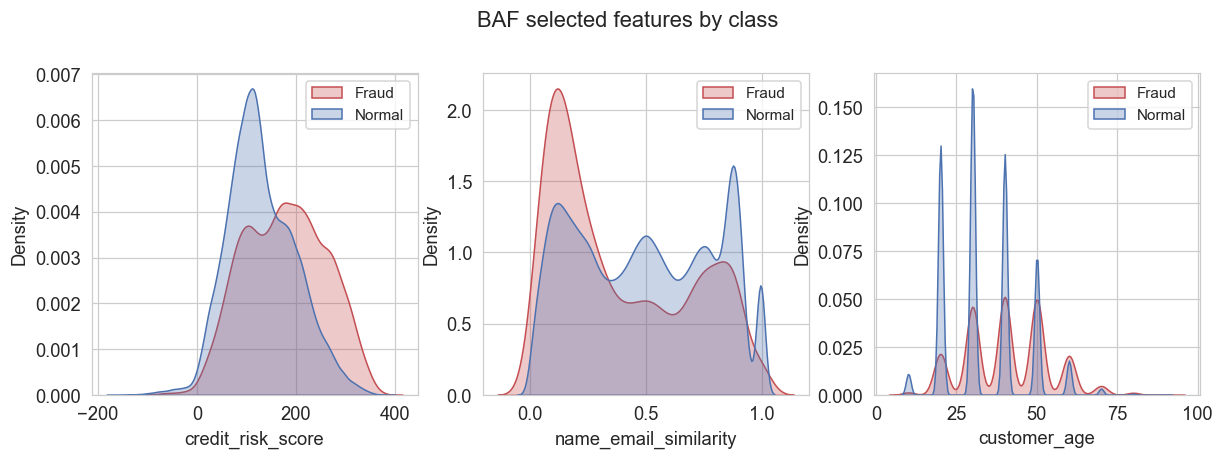

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, c in zip(axes, ["credit_risk_score", "name_email_similarity", "customer_age"]):
    sns.kdeplot(data=baf, x=c, hue="fraud_bool", common_norm=False, fill=True, alpha=0.3,
                palette={0: "#4C72B0", 1: "#C44E52"}, ax=ax)
    ax.legend(["Fraud", "Normal"], fontsize=10); ax.set_ylabel("Density")
fig.suptitle("BAF selected features by class", y=1.03)
savefig("baf_features_by_class.png"); plt.show()

## B.2 Split and preprocessing

In [25]:
for c in neg_cols:
    baf[c] = baf[c].replace(-1, np.nan)

baf_cat = ["payment_type", "employment_status", "housing_status", "source", "device_os"]
baf_num = [c for c in baf.columns if c not in baf_cat + ["fraud_bool", "month"]]

tr_period = baf[baf["month"] <= 5]
va_period = baf[baf["month"] == 6]
te_period = baf[baf["month"] == 7]

tr_normal = tr_period[tr_period["fraud_bool"] == 0]
const = [c for c in baf_num if tr_normal[c].nunique(dropna=True) <= 1]
baf_num = [c for c in baf_num if c not in const]
print("Constant columns dropped:", const)

es_mask = np.random.RandomState(SEED).rand(len(tr_normal)) < 0.10
fit_part, es_part = tr_normal[~es_mask], tr_normal[es_mask]
print("Training-period fraud removed from training:", int(tr_period["fraud_bool"].sum()))

baf_p, X_tr = fit_preprocessor(fit_part, baf_num, cat_cols=[], onehot_cols=baf_cat)
X_es = transform(es_part, baf_p)
X_va = transform(va_period, baf_p); y_va = va_period["fraud_bool"].values.astype("int8")
X_te = transform(te_period, baf_p); y_te = te_period["fraud_bool"].values.astype("int8")
print("Features after one-hot encoding:", X_tr.shape[1])

np.savez_compressed(os.path.join(OUT_DIR, "baf.npz"),
                    X_train=X_tr, X_es=X_es, X_val=X_va, y_val=y_va, X_test=X_te, y_test=y_te,
                    feature_names=np.array(baf_p["feature_names"]))

baf_summary = split_summary("BAF Base", {
    "train (normals)": np.zeros(len(X_tr)), "early-stop (normals)": np.zeros(len(X_es)),
    "validation": y_va, "test": y_te})
print("Any NaN left:", np.isnan(X_tr).any() or np.isnan(X_va).any() or np.isnan(X_te).any())
baf_summary

Constant columns dropped: ['device_fraud_count']
Training-period fraud removed from training: 8151
Features after one-hot encoding: 50
Any NaN left: False


,dataset,split,rows,fraud,fraud_rate_%
0,BAF Base,train (normals),708343,0,0.000
1,BAF Base,early-stop (normals),78495,0,0.000
2,BAF Base,validation,108168,1450,1.341
3,BAF Base,test,96843,1428,1.475


---
# Summary table for the thesis

This table is saved as `Processed/split_summary.csv`, ready for the data preparation section of Chapter 4.

In [27]:
summary = pd.concat([ieee_summary, baf_summary], ignore_index=True)
summary.to_csv(os.path.join(OUT_DIR, "split_summary.csv"), index=False)

meta = {"ieee": {"n_features": len(ieee_p["feature_names"]), "dropped_high_missing": len(high_miss),
                 "n_numeric": len(ieee_num), "n_categorical": len(ieee_cat)},
        "baf":  {"n_features": len(baf_p["feature_names"]), "constant_dropped": const,
                 "minus1_as_missing": neg_cols}}
with open(os.path.join(OUT_DIR, "prep_meta.json"), "w") as f:
    json.dump(meta, f, indent=2)
print(json.dumps(meta, indent=2))
summary

{
  "ieee": {
    "n_features": 419,
    "dropped_high_missing": 12,
    "n_numeric": 378,
    "n_categorical": 41
  },
  "baf": {
    "n_features": 50,
    "constant_dropped": [
      "device_fraud_count"
    ],
    "minus1_as_missing": [
      "prev_address_months_count",
      "current_address_months_count",
      "bank_months_count",
      "session_length_in_minutes",
      "device_distinct_emails_8w"
    ]
  }
}


,dataset,split,rows,fraud,fraud_rate_%
0,IEEE-CIS,train (normals),358788,0,0.000
1,IEEE-CIS,early-stop (normals),40052,0,0.000
2,IEEE-CIS,validation,88581,3042,3.434
3,IEEE-CIS,test,88581,3083,3.480
4,BAF Base,train (normals),708343,0,0.000
5,BAF Base,early-stop (normals),78495,0,0.000
6,BAF Base,validation,108168,1450,1.341
7,BAF Base,test,96843,1428,1.475
